In [1]:
import sys
import os

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from sklearn.cross_decomposition import PLSCanonical


sys.path.append(os.path.join(os.getcwd(), './worm-2025-fieseler/import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils
import h5py

In [2]:
neuron = 45

In [10]:
# dirpath = '/lisc/scratch/neurobiology/zimmer/fieseler/wbfm_projects/2022-11-30_spacer_7b_2per_agar/ZIM2165_Gcamp7b_worm1-2022-11-30/final_dataframes/traces'
dirpath = '/lisc/scratch/neurobiology/zimmer/fieseler/wbfm_projects/2022-11-30_spacer_7b_2per_agar/ZIM2165_Gcamp7b_worm1-2022-11-30/final_dataframes/'
filepath = os.path.join(dirpath, 'df_final.h5')
filepaths = [os.path.join(dirpath, filename) for filename in os.listdir(dirpath)]

def print_structure(name, _):
	print(name)

files = list()
axis = dict()
data = dict()
for filepath in filepaths:
	filename = filepath.split('/')[-1]
	print(f'{filename}:')
	file = h5py.File(filepath, 'r')
	file.visititems(print_structure)
	files.append(file)
	print('\n')

	axis[filename] = file['df_with_missing/block0_items'][:]
	data[filename] = file['df_with_missing/block0_values'][:]

df_final.h5:
df_with_missing
df_with_missing/axis0_label0
df_with_missing/axis0_label1
df_with_missing/axis0_label2
df_with_missing/axis0_level0
df_with_missing/axis0_level1
df_with_missing/axis0_level2
df_with_missing/axis1
df_with_missing/block0_items_label0
df_with_missing/block0_items_label1
df_with_missing/block0_items_label2
df_with_missing/block0_items_level0
df_with_missing/block0_items_level1
df_with_missing/block0_items_level2
df_with_missing/block0_values
df_with_missing/block1_items_label0
df_with_missing/block1_items_label1
df_with_missing/block1_items_label2
df_with_missing/block1_items_level0
df_with_missing/block1_items_level1
df_with_missing/block1_items_level2
df_with_missing/block1_values




KeyError: "Unable to synchronously open object (object 'block0_items' doesn't exist)"

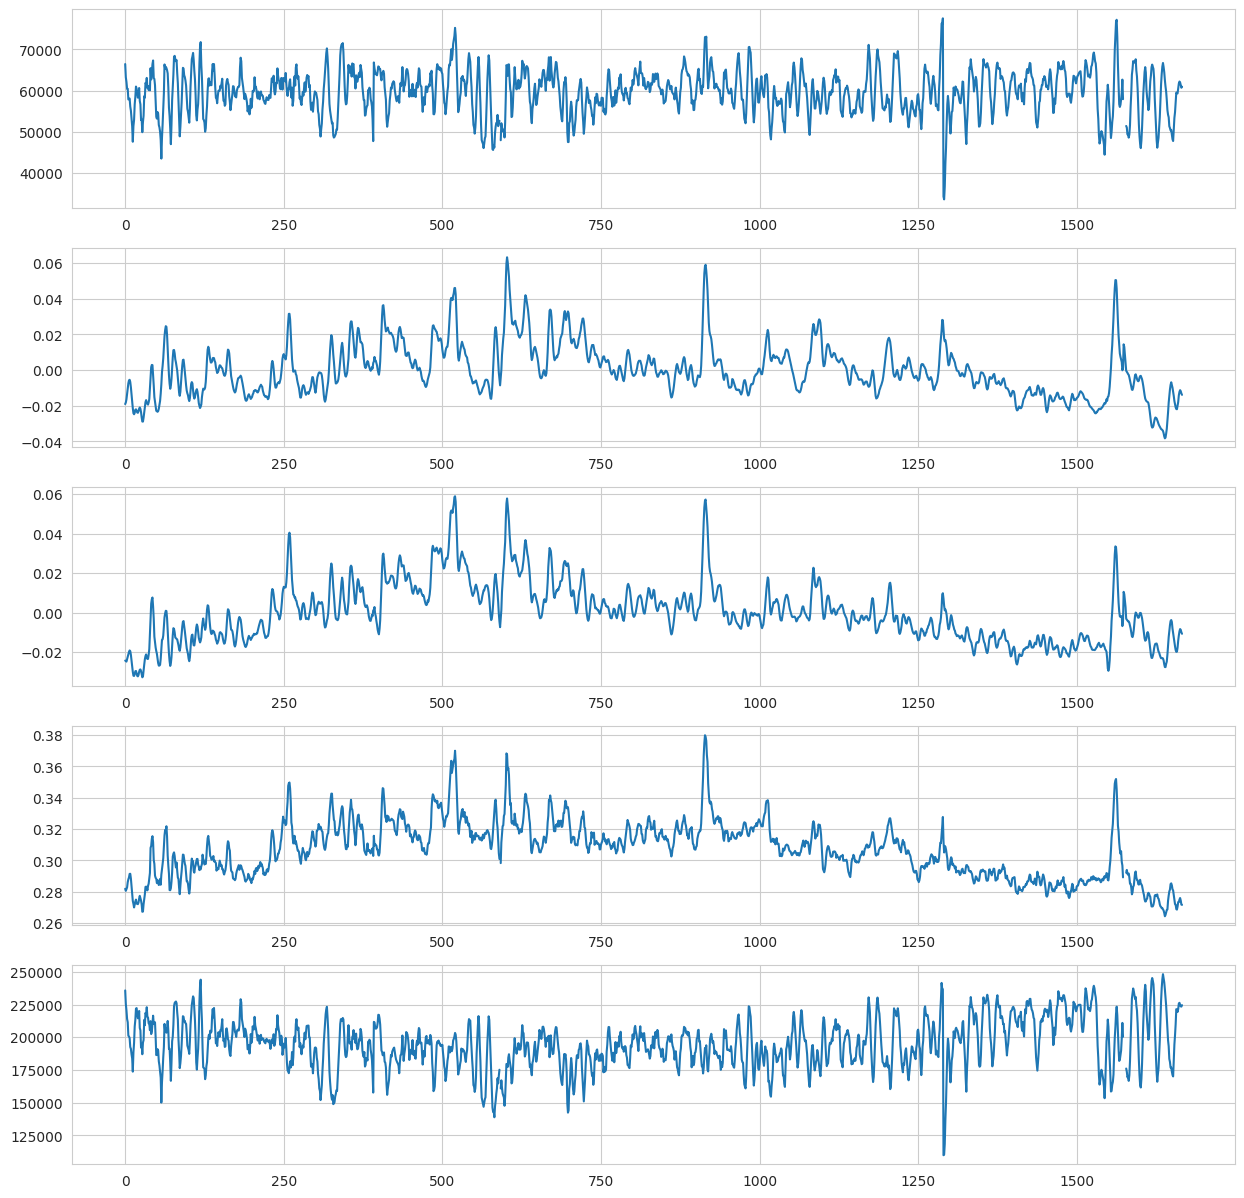

In [4]:
fig, ax = plt.subplots(len(filepaths), 1, figsize=(15, 15))

for i, filepath in enumerate(filepaths):
	filename = filepath.split('/')[-1]

	ax[i].plot(data[filename][:, neuron])

In [5]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_data(path)

# clear nan values
for i in range(len(file_ids)):
	mask = eigenworms[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# remove unused discrete state labels
# discrete_states = [ds[selection_bhl] for ds in discrete_states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

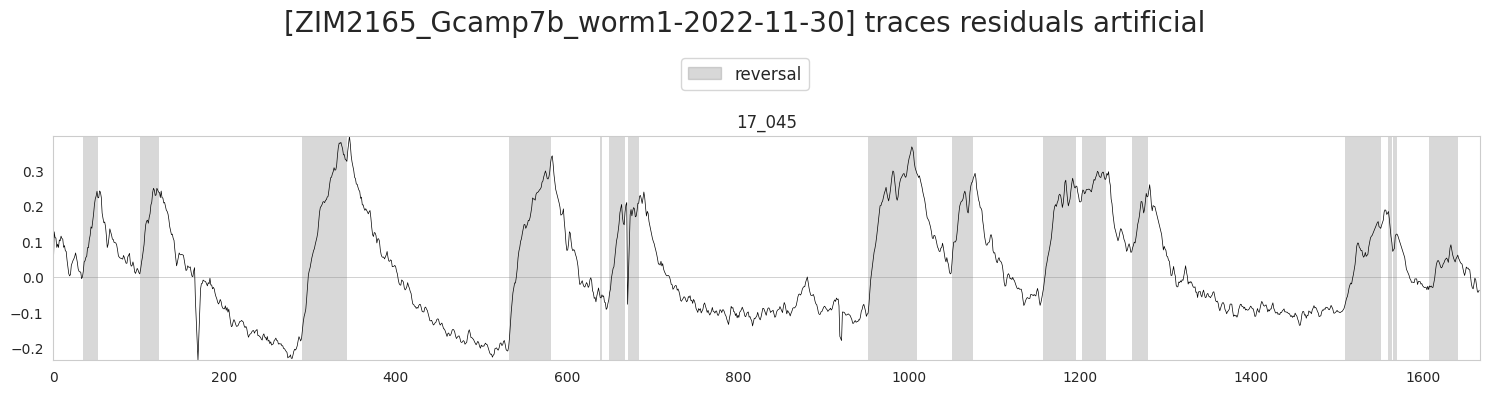

In [6]:
plot_id = 17

plot_utils.plot_traces(f'[{filenames[file_ids.index(plot_id)]}] traces residuals artificial',
					   discrete_states[file_ids.index(plot_id)]['REV'],
					   traces[file_ids.index(plot_id)][[f'17_{neuron:03d}']],
					   plots_per_row=1, ylimits=None)